In [86]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.estimators import HillClimbSearch, MmhcEstimator, BIC, BDeu, K2, AIC, BDs, BayesianEstimator, ExpectationMaximization
from pgmpy.inference import VariableElimination
import networkx as nx
import copy
import logging

# Suppress all pgmpy INFO messages
logging.getLogger("pgmpy").setLevel(logging.WARNING)

TODO: Explain what we did in preprocess
TODO: introduce what we're doing here

In [87]:
df = pd.read_csv('datasets\mxmh_clean.csv')

<>:1: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:1: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
C:\Users\Andrej\AppData\Local\Temp\ipykernel_57576\308175525.py:1: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
  df = pd.read_csv('datasets\mxmh_clean.csv')


In [88]:
df.head()

,Hours per day,While working,Instrumentalist,Composer,Fav genre,Exploratory,BPM,Anxiety,Depression,Insomnia,OCD
0,3.000,Yes,Yes,Yes,Latin,Yes,156.000,1,0,0,0
1,1.500,Yes,No,No,Rock,Yes,119.000,2,1,1,0
2,4.000,No,No,No,Video game music,No,132.000,2,2,3,0
3,2.500,Yes,No,Yes,Jazz,Yes,84.000,3,2,1,0
4,4.000,Yes,No,No,R&B,Yes,107.000,2,1,2,1


In [89]:
df.describe()

,Hours per day,BPM,Anxiety,Depression,Insomnia,OCD
count,609.000,609.000,609.000,609.000,609.000,609.000
mean,3.498,123.929,2.005,1.704,1.317,0.315
std,2.504,32.072,0.897,0.979,1.070,0.465
min,0.000,40.000,0.000,0.000,0.000,0.000
25%,2.000,100.000,2.000,1.000,0.000,0.000
50%,3.000,120.000,2.000,2.000,1.000,0.000
75%,5.000,144.000,3.000,2.000,2.000,1.000
max,12.000,220.000,3.000,3.000,3.000,1.000


Our goal in this project is to investigate the causal relation between music taste and mental illness and experiment with different ways of modeling it. This is acheived by a three step process by:

1. Determining the direction of the causal relation by infering causality (different from establishing causality)
3. Learn a network with pgmpy and compare it to our results
2. Investigating different setups using estimation approaches and latent variables (+ BIC score evaluation of the networks)

In [90]:
personal_causes = [
    ('Instrumentalist', 'Composer'),
    ('Instrumentalist', 'Hours per day'),
    ('Instrumentalist', 'Fav genre'),
    ('Composer', 'Hours per day'),
    ('Composer', 'Fav genre'),
    ('While working', 'Hours per day'),
]

genre_causes = [
    ('Fav genre', 'BPM')
]

mental_health_causes_taste = [
    ('Anxiety', 'Fav genre'),
    ('Anxiety', 'BPM'),
    ('Anxiety', 'Hours per day'),
    ('Anxiety', 'Exploratory'),
    ('Depression', 'Fav genre'),
    ('Depression', 'BPM'),
    ('Depression', 'Hours per day'),
    ('Depression', 'Exploratory'),
    ('Insomnia', 'Fav genre'),
    ('Insomnia', 'BPM'),
    ('Insomnia', 'Hours per day'),
    ('Insomnia', 'Exploratory'),
    ('OCD', 'Fav genre'),
    ('OCD', 'BPM'),
    ('OCD', 'Hours per day'),
    ('OCD', 'Exploratory')
] + personal_causes + genre_causes


taste_causes_mental_health = [
    ('Fav genre', 'Anxiety'),
    ('BPM', 'Anxiety'),
    ('Hours per day', 'Anxiety'),
    ('Exploratory', 'Anxiety'),
    ('Fav genre', 'Depression'),
    ('BPM', 'Depression'),
    ('Hours per day', 'Depression'),
    ('Exploratory', 'Depression'),
    ('Fav genre', 'Insomnia'),
    ('BPM', 'Insomnia'),
    ('Hours per day', 'Insomnia'),
    ('Exploratory', 'Insomnia'),
    ('Fav genre', 'OCD'),
    ('BPM', 'OCD'),
    ('Hours per day', 'OCD'),
    ('Exploratory', 'OCD')
] + personal_causes + genre_causes

latent_edges = [
    ('Internalization', 'Depression'),
    ('Internalization', 'Anxiety'),
    ('Internalization', 'Insomnia'),
    ('Internalization', 'OCD')
]

mental_health_causes_taste_latent = mental_health_causes_taste + latent_edges
taste_causes_mental_health_latent = taste_causes_mental_health + latent_edges

In [91]:
BN_mhct = DiscreteBayesianNetwork(mental_health_causes_taste)
BN_tcmh = DiscreteBayesianNetwork(taste_causes_mental_health)
BN_mhct_latent = DiscreteBayesianNetwork(mental_health_causes_taste_latent, latents = {"Internalization"})
BN_tcmh_latent = DiscreteBayesianNetwork(taste_causes_mental_health_latent, latents= {"Internalization"})

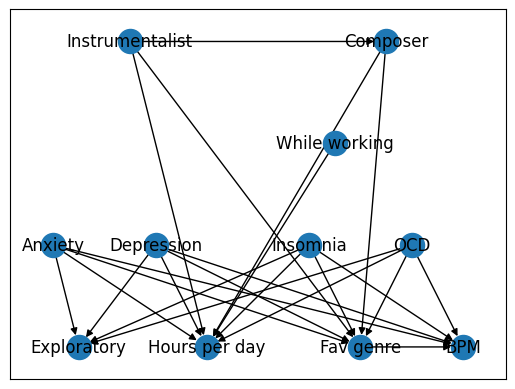

In [92]:
G = nx.DiGraph()
G.add_edges_from(BN_mhct.edges())
pos = {'Age': [0.5, -0.5],
        'Instrumentalist': [0.25, -1],
        'Composer': [0.75, -1],
        'While working': [0.65, - 1.5],
        'Anxiety': [0.1, -2],
        'Depression': [0.3, -2],
        'Insomnia': [0.6, -2],
        'OCD': [0.8, -2],
        'Exploratory': [0.15, -2.5],
        'Hours per day': [0.4, -2.5],
        'Fav genre': [0.7, -2.5],
        'BPM': [0.9, -2.5]
}
# plt.subplots(1, 1, figsize=(12, 12))
nx.draw_networkx(G, pos=pos)


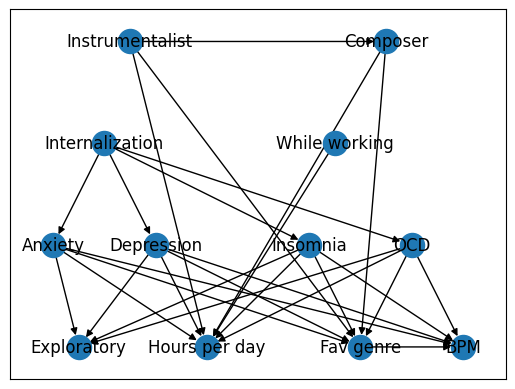

In [93]:
G = nx.DiGraph()
G.add_edges_from(BN_mhct_latent.edges())
pos = {'Age': [0.5, -0.5],
        'Instrumentalist': [0.25, -1],
        'Composer': [0.75, -1],
        'While working': [0.65, - 1.5],
        'Internalization': [0.2, -1.5],
        'Anxiety': [0.1, -2],
        'Depression': [0.3, -2],
        'Insomnia': [0.6, -2],
        'OCD': [0.8, -2],
        'Exploratory': [0.15, -2.5],
        'Hours per day': [0.4, -2.5],
        'Fav genre': [0.7, -2.5],
        'BPM': [0.9, -2.5]
}
# plt.subplots(1, 1, figsize=(12, 12))
nx.draw_networkx(G, pos=pos)

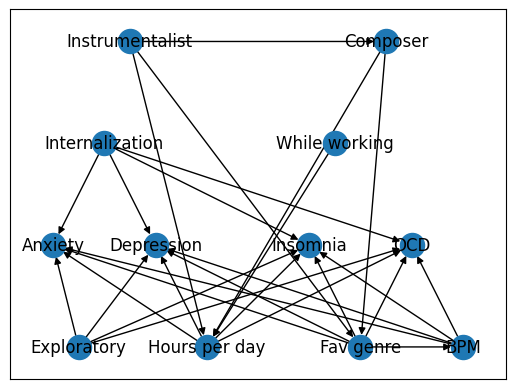

In [94]:
G = nx.DiGraph()
G.add_edges_from(BN_tcmh_latent.edges())
pos = {'Age': [0.5, -0.5],
        'Instrumentalist': [0.25, -1],
        'Composer': [0.75, -1],
        'While working': [0.65, - 1.5],
        'Internalization': [0.2, -1.5],
        'Anxiety': [0.1, -2],
        'Depression': [0.3, -2],
        'Insomnia': [0.6, -2],
        'OCD': [0.8, -2],
        'Exploratory': [0.15, -2.5],
        'Hours per day': [0.4, -2.5],
        'Fav genre': [0.7, -2.5],
        'BPM': [0.9, -2.5]
}
# plt.subplots(1, 1, figsize=(12, 12))
nx.draw_networkx(G, pos = pos)

In [95]:
mhct_copy = copy.deepcopy(BN_mhct)
tcmh_copy = copy.deepcopy(BN_tcmh)
mhct_latent_copy = copy.deepcopy(BN_mhct_latent)
tcmh_latent_copy = copy.deepcopy(BN_tcmh_latent)

mhct_estimator = BayesianEstimator(mhct_copy, df)
tcmh_estimator = BayesianEstimator(tcmh_copy, df)

mhct_latent_estimator = ExpectationMaximization(mhct_latent_copy, df)
tcmh_latent_estimator = ExpectationMaximization(tcmh_latent_copy, df)

mhct_estimation = mhct_estimator.get_parameters()
tcmh_estimation = tcmh_estimator.get_parameters()

mhct_latent_estimation = mhct_latent_estimator.get_parameters(latent_card ={"Internalization": 2})
tcmh_latent_estimation = tcmh_latent_estimator.get_parameters(latent_card={"Internalization": 2})

100%|██████████| 100/100 [06:46<00:00,  4.06s/it]


In [96]:
for cpd in mhct_estimation:
    mhct_copy.add_cpds(cpd)

for cpd in tcmh_estimation:
    tcmh_copy.add_cpds(cpd)

# For latent networks
for cpd in mhct_latent_estimation:
    mhct_latent_copy.add_cpds(cpd)

for cpd in tcmh_latent_estimation:
    tcmh_latent_copy.add_cpds(cpd)

In [97]:
mmhc = MmhcEstimator(df)
skeleton = mmhc.mmpc()
print("Part 1) Skeleton: ", skeleton.edges())

# use hill climb search to orient the edges:
hc = HillClimbSearch(df)
learned_network = hc.estimate(tabu_length=10, scoring_method=BDeu(df))
print("Part 2) Model:    ", learned_network.edges())

Part 1) Skeleton:  [('Hours per day', 'Composer'), ('Hours per day', 'Instrumentalist'), ('Hours per day', 'Insomnia'), ('Hours per day', 'BPM'), ('Hours per day', 'Anxiety'), ('While working', 'Depression'), ('Instrumentalist', 'BPM'), ('Fav genre', 'Exploratory'), ('Fav genre', 'Depression'), ('Fav genre', 'OCD'), ('Exploratory', 'BPM'), ('BPM', 'Anxiety'), ('Anxiety', 'Insomnia'), ('Insomnia', 'OCD')]


  0%|          | 8/1000000 [00:00<19:01:36, 14.60it/s]

Part 2) Model:     [('Hours per day', 'While working'), ('While working', 'Exploratory'), ('While working', 'OCD'), ('While working', 'Instrumentalist'), ('Instrumentalist', 'Composer'), ('Anxiety', 'Depression'), ('Depression', 'Insomnia'), ('OCD', 'Anxiety')]


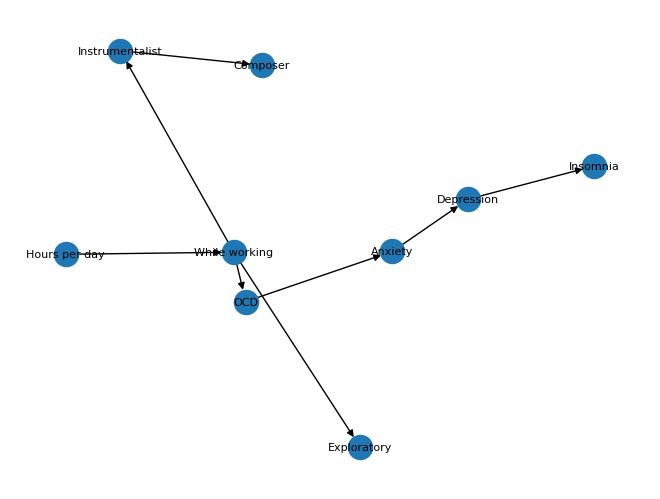

In [98]:
G = nx.DiGraph()
G.add_edges_from(learned_network.edges())
pos = nx.spring_layout(G)  
nx.draw(
    G, 
    pos,
    with_labels=True,
    font_size  = 8
)

In [99]:
# Number of bootstrap resamples
n_bootstrap = 50
random_state = 42
rng = np.random.default_rng(random_state)

# Containers for bootstrap scores
bootstrap_scores = {
    'BIC': {'MHCT': [], 'TCMH': []},
    'BDeu': {'MHCT': [], 'TCMH': []},
    'K2': {'MHCT': [], 'TCMH': []},
    'AIC': {'MHCT': [], 'TCMH': []},
    'BDs': {'MHCT': [], 'TCMH': []}
}

# Perform bootstrapping
for i in range(n_bootstrap):
    sample_idx = rng.choice(df.index, size=len(df), replace=True)
    df_sample = df.iloc[sample_idx].reset_index(drop=True)

    # Compute all scores for this bootstrap sample
    bic_mhct = BIC(df_sample).score(mhct_copy)
    bic_tcmh = BIC(df_sample).score(tcmh_copy)

    bdeu_mhct = BDeu(df_sample).score(mhct_copy)
    bdeu_tcmh = BDeu(df_sample).score(tcmh_copy)

    k2_mhct = K2(df_sample).score(mhct_copy)
    k2_tcmh = K2(df_sample).score(tcmh_copy)

    aic_mhct = AIC(df_sample).score(mhct_copy)
    aic_tcmh = AIC(df_sample).score(tcmh_copy)

    bds_mhct = BDs(df_sample).score(mhct_copy)
    bds_tcmh = BDs(df_sample).score(tcmh_copy)

    # Store results
    bootstrap_scores['BIC']['MHCT'].append(bic_mhct)
    bootstrap_scores['BIC']['TCMH'].append(bic_tcmh)

    bootstrap_scores['BDeu']['MHCT'].append(bdeu_mhct)
    bootstrap_scores['BDeu']['TCMH'].append(bdeu_tcmh)

    bootstrap_scores['K2']['MHCT'].append(k2_mhct)
    bootstrap_scores['K2']['TCMH'].append(k2_tcmh)

    bootstrap_scores['AIC']['MHCT'].append(aic_mhct)
    bootstrap_scores['AIC']['TCMH'].append(aic_tcmh)

    bootstrap_scores['BDs']['MHCT'].append(bds_mhct)
    bootstrap_scores['BDs']['TCMH'].append(bds_tcmh)

# Compute means and standard deviations
rows = []
for score_type, values in bootstrap_scores.items():
    mhct_mean = np.mean(values['MHCT'])
    tcmh_mean = np.mean(values['TCMH'])
    mhct_std = np.std(values['MHCT'])
    tcmh_std = np.std(values['TCMH'])
    better = 'MHCT' if mhct_mean > tcmh_mean else 'TCMH'
    rows.append({
        'Score Type': score_type,
        'MHCT (mean)': mhct_mean,
        'MHCT (std)': mhct_std,
        'TCMH (mean)': tcmh_mean,
        'TCMH (std)': tcmh_std,
        'Better Model': better
    })

# Create summary DataFrame
score_comparison = pd.DataFrame(rows)

score_comparison


,Score Type,MHCT (mean),MHCT (std),TCMH (mean),TCMH (std),Better Model
0,BIC,"-815,331.163","28,471.113","-1,983,782.524","125,293.636",MHCT
1,BDeu,"-10,378.883",125.788,"-9,539.025",87.366,TCMH
2,K2,"767,647.605","36,107.051","319,192.623","20,969.638",MHCT
3,AIC,"-257,844.101","8,883.172","-622,802.986","39,081.770",MHCT
4,BDs,"-20,861.686",165.717,"-897,891.565","56,609.632",MHCT


In [100]:
# Convert DAG to BayesianNetwork
learned_bn = DiscreteBayesianNetwork(learned_network.edges())

# Fit CPDs using data
estimator = BayesianEstimator(learned_bn, df)
cpds = estimator.get_parameters()
for cpd in cpds:
    learned_bn.add_cpds(cpd)

In [101]:
custom_priors = {
    "Anxiety": 5* np.array([[84, 10, 3, 3]]).T,
    "Depression": 5 *np.array([[81, 12, 4, 3]]).T,
    "Insomnia": 5 *np.array([[82, 10, 2, 6]]).T,
    "OCD": 5 * np.array([[97, 3]]).T
}

# Create the estimator
mhct_prior_copy = copy.deepcopy(mhct_copy)
mhct_prior_estimator = BayesianEstimator(mhct_copy, df)

# Fit with custom priors (applied only to the specified variables)
for node in mhct_prior_copy.nodes():
    if node in custom_priors:
      cpd = mhct_prior_estimator.estimate_cpd(
          node,
          prior_type="dirichlet",
          pseudo_counts=custom_priors[node]  # only for selected variables
      )
    else:
        # Default prior for other nodes
        cpd = mhct_prior_estimator.estimate_cpd(node, prior_type="BDeu", equivalent_sample_size=10)
    mhct_prior_copy.add_cpds(cpd)

In [102]:
print(mhct_copy.get_cpds('Anxiety'))

+------------+-----------+
| Anxiety(0) | 0.0818404 |
+------------+-----------+
| Anxiety(1) | 0.158388  |
+------------+-----------+
| Anxiety(2) | 0.436889  |
+------------+-----------+
| Anxiety(3) | 0.322883  |
+------------+-----------+


In [103]:
print(mhct_prior_copy.get_cpds('Anxiety'))

+------------+----------+
| Anxiety(0) | 0.422904 |
+------------+----------+
| Anxiety(1) | 0.13165  |
+------------+----------+
| Anxiety(2) | 0.254283 |
+------------+----------+
| Anxiety(3) | 0.191163 |
+------------+----------+


In [104]:
def compare_multiple_networks_bootstrap_ll(df, models, n_bootstrap=50, random_state=42):
    """
    Compare multiple Bayesian networks using bootstrapped log-likelihood.

    Parameters
    ----------
    df : pd.DataFrame
        Observed dataset with categorical columns (strings or integers)
    models : list of tuples
        List of (name, BayesianNetwork) to compare. Each network must have CPDs attached.
        Example: [('MHCT', mhct_copy), ('MHCT_latent', mhct_latent_copy), ('Learned', learned_network)]
    n_bootstrap : int
        Number of bootstrap resamples
    random_state : int
        Random seed

    Returns
    -------
    pd.DataFrame
        Summary table with mean, std log-likelihood per model and which model is better
    """
    rng = np.random.default_rng(random_state)

    # Helper function to compute log-likelihood for one network
    def log_likelihood(model, df_sample):
        ll = 0
        inf = VariableElimination(model)
        observed_vars = [v for v in df_sample.columns if v in model.nodes()]

        for _, row in df_sample.iterrows():
            prob = 1.0
            for var in observed_vars:
                parents = list(model.get_parents(var))
                evidence = {p: row[p] for p in parents if p in observed_vars}

                q = inf.query([var], evidence=evidence, show_progress=False)
                cpd = model.get_cpds(var)

                # Map row value to CPD index
                if cpd.state_names:
                    val_idx = cpd.state_names[var].index(row[var])
                else:
                    val_idx = int(row[var])

                prob *= q.values[val_idx]

            ll += np.log(prob + 1e-12)  # small epsilon to avoid log(0)
        return ll

    # Initialize container for log-likelihoods
    logliks = {name: [] for name, _ in models}

    # Bootstrapping loop
    for i in range(n_bootstrap):
        sample_idx = rng.choice(df.index, size=len(df), replace=True)
        df_sample = df.iloc[sample_idx].reset_index(drop=True)

        for name, model in models:
            ll = log_likelihood(model, df_sample)
            logliks[name].append(ll)

    # Compute summary statistics
    rows = []
    for model_name, scores in logliks.items():
        rows.append({
            'Model': model_name,
            'Mean LogLik': np.mean(scores),
            'Std LogLik': np.std(scores)
        })

    summary_df = pd.DataFrame(rows)
    summary_df['Better Model'] = summary_df['Mean LogLik'] == summary_df['Mean LogLik'].max()

    pd.set_option('display.float_format', lambda x: f"{x:,.3f}")
    return summary_df

In [105]:
models = [
    ('MHCT', mhct_copy),
    ('MHCT (Latent)', mhct_latent_copy),
    ('MHCT (Prior)', mhct_prior_copy),
    ('Learned', learned_bn)
]

compare_multiple_networks_bootstrap_ll(df, models, n_bootstrap=20)

,Model,Mean LogLik,Std LogLik,Better Model
0,MHCT,"-5,592.991",26.512,False
1,MHCT (Latent),"-5,588.341",26.668,False
2,MHCT (Prior),"-6,009.695",32.312,False
3,Learned,"-5,134.291",34.494,True


In [107]:
for cpd in mhct_copy.get_cpds():
    print(cpd)

+------------+-----------+
| Anxiety(0) | 0.0818404 |
+------------+-----------+
| Anxiety(1) | 0.158388  |
+------------+-----------+
| Anxiety(2) | 0.436889  |
+------------+-----------+
| Anxiety(3) | 0.322883  |
+------------+-----------+
+-----------------------------+-----+-----------------------+
| Anxiety                     | ... | Anxiety(3)            |
+-----------------------------+-----+-----------------------+
| Composer                    | ... | Composer(Yes)         |
+-----------------------------+-----+-----------------------+
| Depression                  | ... | Depression(3)         |
+-----------------------------+-----+-----------------------+
| Insomnia                    | ... | Insomnia(3)           |
+-----------------------------+-----+-----------------------+
| Instrumentalist             | ... | Instrumentalist(Yes)  |
+-----------------------------+-----+-----------------------+
| OCD                         | ... | OCD(1)                |
+------------

In [108]:
for cpd in mhct_latent_copy.get_cpds():
    print(cpd)

+-----------------+---------------------+----------------------+
| Instrumentalist | Instrumentalist(No) | Instrumentalist(Yes) |
+-----------------+---------------------+----------------------+
| Composer(No)    | 0.941031941031941   | 0.599009900990099    |
+-----------------+---------------------+----------------------+
| Composer(Yes)   | 0.05896805896805897 | 0.400990099009901    |
+-----------------+---------------------+----------------------+
+-----------------------------+-----+----------------------+
| Anxiety                     | ... | Anxiety(3)           |
+-----------------------------+-----+----------------------+
| Composer                    | ... | Composer(Yes)        |
+-----------------------------+-----+----------------------+
| Depression                  | ... | Depression(3)        |
+-----------------------------+-----+----------------------+
| Insomnia                    | ... | Insomnia(3)          |
+-----------------------------+-----+--------------------

In [109]:
for cpd in mhct_prior_copy.get_cpds():
    print(cpd)

+------------+----------+
| Anxiety(0) | 0.422904 |
+------------+----------+
| Anxiety(1) | 0.13165  |
+------------+----------+
| Anxiety(2) | 0.254283 |
+------------+----------+
| Anxiety(3) | 0.191163 |
+------------+----------+
+-----------------------------+-----+------------------------+
| Anxiety                     | ... | Anxiety(3)             |
+-----------------------------+-----+------------------------+
| Composer                    | ... | Composer(Yes)          |
+-----------------------------+-----+------------------------+
| Depression                  | ... | Depression(3)          |
+-----------------------------+-----+------------------------+
| Insomnia                    | ... | Insomnia(3)            |
+-----------------------------+-----+------------------------+
| Instrumentalist             | ... | Instrumentalist(Yes)   |
+-----------------------------+-----+------------------------+
| OCD                         | ... | OCD(1)                 |
+---------

In [110]:
for cpd in learned_bn.get_cpds():
    print(cpd)

+---------------------+------------+
| Hours per day(0.0)  | 0.00370974 |
+---------------------+------------+
| Hours per day(0.25) | 0.00370974 |
+---------------------+------------+
| Hours per day(0.5)  | 0.026511   |
+---------------------+------------+
| Hours per day(0.7)  | 0.00208107 |
+---------------------+------------+
| Hours per day(1.0)  | 0.160062   |
+---------------------+------------+
| Hours per day(1.5)  | 0.0248824  |
+---------------------+------------+
| Hours per day(2.0)  | 0.215436   |
+---------------------+------------+
| Hours per day(2.5)  | 0.00859573 |
+---------------------+------------+
| Hours per day(3.0)  | 0.169834   |
+---------------------+------------+
| Hours per day(4.0)  | 0.122602   |
+---------------------+------------+
| Hours per day(5.0)  | 0.0769996  |
+---------------------+------------+
| Hours per day(6.0)  | 0.0672277  |
+---------------------+------------+
| Hours per day(7.0)  | 0.021625   |
+---------------------+------------+
|